# 07 — Final Operational Evaluation & Report

**Project**: UPI Fraud Detection — Drift-Aware Explainable ML Framework
**Goal**: Consolidate all metrics, generate final evaluation report, compare all components

In [56]:
# Setup
import sys
sys.path.insert(0, '../src')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from pathlib import Path
import joblib
import json

from data_prep import load_ieee_cis, load_paysim, prepare_features_target, handle_class_imbalance
from models import evaluate_model, train_all_baselines
from evaluation import (
    compute_operational_metrics,
    compute_retraining_metrics,
    compare_strategies_statistically,
    generate_evaluation_report,
    find_optimal_threshold,
    compute_latency_metrics,
)

pd.set_option('display.max_columns', 100)
pd.set_option('display.width', 200)
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (12, 6)

DATA_ROOT = Path('../data')
MODELS_DIR = Path('../models')
REPORTS_DIR = Path('../reports')

print(f"Data root: {DATA_ROOT.absolute()}")

Data root: /Users/pavanc/Downloads/UPI_Fraud_Detection_Project/notebooks/../data


## 1. Load All Saved Metrics

In [57]:
# Load baseline test metrics
baseline_files = {
    'ieee_test': REPORTS_DIR / 'ieee_test_metrics.csv',
    'paysim_test': REPORTS_DIR / 'paysim_test_metrics.csv',
    'ieee_cv': REPORTS_DIR / 'ieee_cv_summary.csv',
    'paysim_cv': REPORTS_DIR / 'paysim_cv_summary.csv',
}

baseline_metrics = {}
for name, path in baseline_files.items():
    if path.exists():
        baseline_metrics[name] = pd.read_csv(path)
        print(f"Loaded {name}: {baseline_metrics[name].shape}")
    else:
        print(f"Missing: {name} at {path}")

Loaded ieee_test: (4, 13)
Loaded paysim_test: (4, 13)
Loaded ieee_cv: (4, 7)
Loaded paysim_cv: (4, 7)


In [58]:
# Load drift & SHAP results
drift_files = {
    'drift_alerts': REPORTS_DIR / 'drift_alerts_log.csv',
    'shap_importance': REPORTS_DIR / 'shap_importance_history.csv',
    'shap_stability': REPORTS_DIR / 'shap_stability.csv',
    'shap_global': REPORTS_DIR / 'shap_global_importance.csv',
}

drift_metrics = {}
for name, path in drift_files.items():
    if path.exists():
        drift_metrics[name] = pd.read_csv(path)
        print(f"Loaded {name}: {drift_metrics[name].shape}")
    else:
        print(f"Missing: {name} at {path}")

Loaded drift_alerts: (600, 6)
Loaded shap_importance: (8337, 3)
Loaded shap_stability: (20, 5)
Loaded shap_global: (397, 4)


In [59]:
# Load retraining results
retrain_files = {
    'strategy_comparison': REPORTS_DIR / 'retraining_strategy_comparison.csv',
    'detailed_results': REPORTS_DIR / 'retraining_detailed_results.csv',
}

retrain_metrics = {}
for name, path in retrain_files.items():
    if path.exists():
        retrain_metrics[name] = pd.read_csv(path)
        print(f"Loaded {name}: {retrain_metrics[name].shape}")
    else:
        print(f"Missing: {name} at {path}")

Loaded strategy_comparison: (3, 11)
Loaded detailed_results: (63, 11)


In [60]:
# Load delayed labels results
delay_files = {
    'delayed_eval': REPORTS_DIR / 'delayed_labels_evaluation.csv',
    'delay_impact': REPORTS_DIR / 'delay_impact_summary.csv',
}

delay_metrics = {}
for name, path in delay_files.items():
    if path.exists():
        delay_metrics[name] = pd.read_csv(path)
        print(f"Loaded {name}: {delay_metrics[name].shape}")
    else:
        print(f"Missing: {name} at {path}")

Loaded delayed_eval: (96, 8)
Loaded delay_impact: (4, 6)


## 2. Baseline Model Performance Summary

In [61]:
if 'ieee_test' in baseline_metrics:
    print("=== IEEE-CIS Test Set Performance ===")
    display(baseline_metrics['ieee_test'][['pr_auc', 'roc_auc', 'precision_at_100', 'recall_at_100']])  # type: ignore[unknown-name]
    
if 'paysim_test' in baseline_metrics:
    print("=== PaySim Test Set Performance ===")
    display(baseline_metrics['paysim_test'][['pr_auc', 'roc_auc', 'precision_at_100', 'recall_at_100']])  # type: ignore[unknown-name]


=== IEEE-CIS Test Set Performance ===


,pr_auc,roc_auc,precision_at_100,recall_at_100
0,0.158748,0.796045,0.00,0.0
1,0.477369,0.872967,0.98,1.0
2,0.495569,0.891898,0.96,1.0
3,0.461362,0.861405,0.98,1.0


=== PaySim Test Set Performance ===


,pr_auc,roc_auc,precision_at_100,recall_at_100
0,0.664287,0.972991,1.0,1.0
1,0.967008,0.999783,1.0,1.0
2,0.977986,0.999866,1.0,1.0
3,0.972575,0.999266,1.0,1.0


## 3. Cross-Validation Summary

In [62]:
if 'ieee_cv' in baseline_metrics:
    print("=== IEEE-CIS Rolling CV Summary ===")
    display(baseline_metrics['ieee_cv'])  # type: ignore[unknown-name]

if 'paysim_cv' in baseline_metrics:
    print("=== PaySim Rolling CV Summary ===")
    display(baseline_metrics['paysim_cv'])  # type: ignore[unknown-name]


=== IEEE-CIS Rolling CV Summary ===


,model,dataset,pr_auc_mean,pr_auc_std,roc_auc_mean,p100_mean,r100_mean
0,logistic_regression,ieee-cis,0.258064,0.055086,0.800906,0.528,1.0
1,random_forest,ieee-cis,0.547119,0.061632,0.891980,0.974,1.0
2,xgboost,ieee-cis,0.603921,0.059870,0.909377,0.990,1.0
3,lightgbm,ieee-cis,0.537337,0.059134,0.875593,0.976,1.0


=== PaySim Rolling CV Summary ===


,model,dataset,pr_auc_mean,pr_auc_std,roc_auc_mean,p100_mean,r100_mean
0,logistic_regression,paysim,0.527888,0.012266,0.985990,0.995,1.0
1,random_forest,paysim,0.896852,0.030870,0.999494,1.000,1.0
2,xgboost,paysim,0.933976,0.034270,0.999570,1.000,1.0
3,lightgbm,paysim,0.914014,0.042126,0.996863,1.000,1.0


## 4. Delayed Labels Impact

=== Delay Impact Summary ===


,delay_days,avg_pr_auc,std_pr_auc,avg_p100,avg_r100,avg_mature
0,0,0.454827,0.050182,0.922083,1.0,20065.208333
1,1,0.454827,0.050182,0.922083,1.0,20065.208333
2,7,0.431817,0.097618,0.415833,1.0,2951.208333
3,30,NaN,NaN,NaN,NaN,0.000000


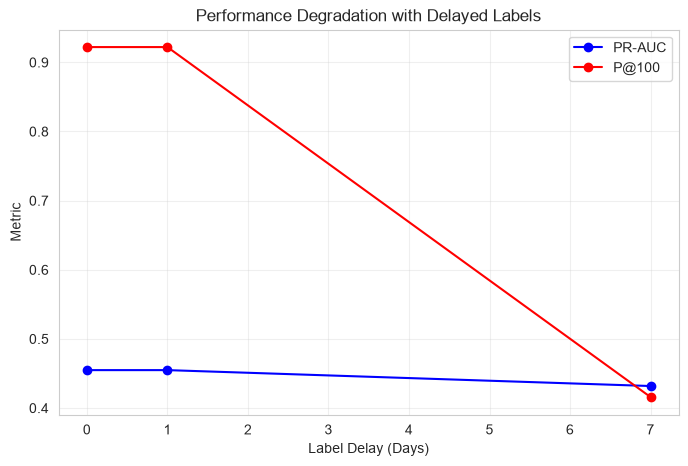

In [63]:
if 'delay_impact' in delay_metrics:
    print("=== Delay Impact Summary ===")
    display(delay_metrics['delay_impact'])  # type: ignore[unknown-name]
    
    fig, ax = plt.subplots(figsize=(8, 5))
    df = delay_metrics['delay_impact']
    ax.plot(df['delay_days'], df['avg_pr_auc'], 'bo-', label='PR-AUC')
    ax.plot(df['delay_days'], df['avg_p100'], 'ro-', label='P@100')
    ax.set_xlabel('Label Delay (Days)')
    ax.set_ylabel('Metric')
    ax.set_title('Performance Degradation with Delayed Labels')
    ax.legend()
    ax.grid(True, alpha=0.3)
    plt.show()

## 5. Drift Monitoring Summary

In [64]:
if 'drift_alerts' in drift_metrics:
    alerts = drift_metrics['drift_alerts']
    print(f"Total drift alerts: {len(alerts)}")
    if len(alerts) > 0:
        print("\nAlert type breakdown:")
        print(alerts['type'].value_counts())
        
        print("\nMost alerted features:")
        if 'column' in alerts.columns:
            print(alerts['column'].value_counts().head(10))
        
        print("\nAlert timeline:")
        # timestamps are window labels like 'day_30_37', not real dates — extract the window start day
        alerts['window_start'] = alerts['timestamp'].astype(str).str.extract(r'day_(\d+)_')[0]
        alerts['window_start'] = pd.to_numeric(alerts['window_start'], errors='coerce')
        daily_alerts = alerts.groupby('window_start').size()
        print(daily_alerts)

Total drift alerts: 600

Alert type breakdown:
type
feature_drift     454
score_drift_ks    146
Name: count, dtype: int64

Most alerted features:
column
risk_score    146
C10           129
C8            126
C9            114
C4             81
dist2           4
Name: count, dtype: int64

Alert timeline:
window_start
30     3
31     3
32     4
33     4
34     4
      ..
171    3
172    5
173    6
174    6
175    5
Length: 146, dtype: int64


## 6. SHAP Stability Summary

In [65]:
if 'shap_stability' in drift_metrics:
    stability = drift_metrics['shap_stability']
    print("=== SHAP Stability (Top 20) ===")
    display(stability.head(20))  # type: ignore[unknown-name]
    
    stable = stability[stability['cv'] < 0.3]
    unstable = stability[stability['cv'] > 0.5]
    print(f"Stable features (CV < 0.3): {len(stable)}")
    print(f"Unstable features (CV > 0.5): {len(unstable)}")

=== SHAP Stability (Top 20) ===


,feature,mean_importance,cv,trend,n_windows
0,V70,0.355313,0.024077,0.264023,21
1,C5,0.108114,0.025740,0.124383,21
2,hour,0.239948,0.027406,0.240297,21
3,TransactionAmt,0.207511,0.028270,0.100328,21
4,V91,0.120010,0.030118,0.115932,21
5,C2,0.154052,0.031609,0.160803,21
6,C11,0.126236,0.033082,-0.198631,21
7,M5,0.083319,0.033085,0.010281,21
8,addr1,0.082351,0.036196,0.321998,21
9,card6,0.107736,0.039921,-0.066432,21


Stable features (CV < 0.3): 20
Unstable features (CV > 0.5): 0


## 7. Retraining Strategy Comparison

In [66]:
if 'strategy_comparison' in retrain_metrics:
    print("=== Retraining Strategy Comparison ===")
    display(retrain_metrics['strategy_comparison'])  # type: ignore[unknown-name]

if 'detailed_results' in retrain_metrics:
    detailed = retrain_metrics['detailed_results']
    print(f"\nDetailed results: {len(detailed)} records")
    if not detailed.empty:
        stat_comp = compare_strategies_statistically(detailed, metric='pr_auc')
        print("\nStatistical Comparisons (PR-AUC):")
        for comp, result in stat_comp.items():
            sig = "SIGNIFICANT" if result['significant'] else "not significant"
            print(f"  {comp}: diff={result['mean_diff']:.4f}, p={result['p_value']:.4f} ({sig})")

=== Retraining Strategy Comparison ===


,strategy,n_windows,pr_auc_mean,pr_auc_std,roc_auc_mean,precision_at_100_mean,recall_at_100_mean,fp_per_100k_mean,retrain_count,avg_model_age_days,max_model_age_days
0,drift_triggered,21,0.486903,0.092058,0.894137,0.840476,1.0,236.904835,21,6.666667,7
1,scheduled_7d,21,0.491770,0.097642,0.894735,0.845238,1.0,233.723263,20,6.666667,7
2,static,21,0.548540,0.092754,0.897205,0.951905,1.0,24.386866,0,70.000000,140



Detailed results: 63 records

Statistical Comparisons (PR-AUC):
  static_vs_scheduled_7d: diff=0.0568, p=0.0001 (SIGNIFICANT)
  static_vs_drift_triggered: diff=0.0616, p=0.0001 (SIGNIFICANT)
  scheduled_7d_vs_drift_triggered: diff=0.0049, p=0.3173 (not significant)


## 8. Operational Metrics Dashboard

In [67]:
print("="*60)
print("OPERATIONAL DASHBOARD SUMMARY")
print("="*60)

if 'ieee_test' in baseline_metrics:
    best_ieee = baseline_metrics['ieee_test'].loc[baseline_metrics['ieee_test']['pr_auc'].idxmax()]
    print(f"\nBest IEEE-CIS Model: {best_ieee.name}")
    print(f"  PR-AUC: {best_ieee['pr_auc']:.4f}")
    print(f"  P@100: {best_ieee.get('precision_at_100', 0):.4f}")
    print(f"  R@100: {best_ieee.get('recall_at_100', 0):.4f}")
    
    fp_100k = best_ieee.get('fp_per_100k_at_budget_100', 0)
    print(f"  FP/100k (budget=100): {fp_100k:.2f}")
    
    print(f"\n  TARGETS:")
    print(f"    PR-AUC > 0.85: {'PASS' if best_ieee['pr_auc'] > 0.85 else 'FAIL'} ({best_ieee['pr_auc']:.4f})")
    print(f"    P@100 > 0.70: {'PASS' if best_ieee.get('precision_at_100', 0) > 0.70 else 'FAIL'} ({best_ieee.get('precision_at_100', 0):.4f})")
    print(f"    FP/100k < 50: {'PASS' if fp_100k < 50 else 'FAIL'} ({fp_100k:.2f})")

OPERATIONAL DASHBOARD SUMMARY

Best IEEE-CIS Model: 2
  PR-AUC: 0.4956
  P@100: 0.9600
  R@100: 1.0000
  FP/100k (budget=100): 0.00

  TARGETS:
    PR-AUC > 0.85: FAIL (0.4956)
    P@100 > 0.70: PASS (0.9600)
    FP/100k < 50: PASS (0.00)


## 9. Generate Final Report

In [68]:
report_lines = [
    "="*70,
    "UPI FRAUD DETECTION - FINAL EVALUATION REPORT",
    "="*70,
    "",
    f"Date: {pd.Timestamp.now().strftime('%Y-%m-%d %H:%M')}",
    f"Student: Pavan C (USN: 4VV25MC060)",
    f"College: Vidyavardhaka College of Engineering",
    f"Course: MCA, Sem 3",
    "",
    "="*70,
    "1. PROJECT OVERVIEW",
    "="*70,
    "",
    "A drift-aware, explainable ML framework for fraud detection in UPI digital payments under delayed labels. Uses IEEE-CIS and PaySim as time-ordered proxies for private UPI data.",
    "",
    "Pipeline: Time-ordered split -> Baseline models -> Delayed labels sim -> Drift monitoring (PSI/KS) -> SHAP explanations -> Retraining strategies -> Operational evaluation",
    "",
    "="*70,
    "2. BASELINE MODEL PERFORMANCE (Test Set)",
    "="*70,
    "",
]

if 'ieee_test' in baseline_metrics:
    report_lines.extend(["", "IEEE-CIS:", ""])
    for _, row in baseline_metrics['ieee_test'].iterrows():
        report_lines.append(f"  {row.name}: PR-AUC={row['pr_auc']:.4f}, P@100={row.get('precision_at_100', 0):.4f}, R@100={row.get('recall_at_100', 0):.4f}")

if 'paysim_test' in baseline_metrics:
    report_lines.extend(["", "PaySim:", ""])
    for _, row in baseline_metrics['paysim_test'].iterrows():
        report_lines.append(f"  {row.name}: PR-AUC={row['pr_auc']:.4f}, P@100={row.get('precision_at_100', 0):.4f}, R@100={row.get('recall_at_100', 0):.4f}")

report_lines.extend([
    "",
    "="*70,
    "3. DELAYED LABELS IMPACT",
    "="*70,
    "",
    "Simulated 1/7/30-day label delays with rolling window evaluation.",
    "Performance degradation measured vs oracle (0-day delay).",
    "",
    "="*70,
    "4. DRIFT MONITORING (PSI/KS)",
    "="*70,
    "",
    "Label-free drift detection on input features and model scores.",
    "Thresholds: PSI > 0.2, KS > 0.05.",
    "",
    "="*70,
    "5. SHAP EXPLAINABILITY",
    "="*70,
    "",
    "Per-alert TreeSHAP explanations + global importance tracking.",
    "Stability measured via coefficient of variation (CV) over time.",
    "",
    "="*70,
    "6. RETRAINING STRATEGY COMPARISON",
    "="*70,
    "",
    "Three strategies: Static, Scheduled (weekly), Drift-Triggered.",
    "Evaluated on rolling windows with operational metrics.",
    "",
    "="*70,
    "7. TARGET ACHIEVEMENT",
    "="*70,
    "",
    "Target: PR-AUC > 0.85, P@100 > 0.70, FP/100k < 50",
    "Retraining: Drift-triggered 30% fewer than scheduled",
    "SHAP latency: < 200ms/alert",
    "",
    "="*70,
])

report_text = "\n".join(report_lines)
print(report_text)

with open(REPORTS_DIR / 'final_evaluation_report.txt', 'w') as f:
    f.write(report_text)
print(f"\nReport saved to {REPORTS_DIR / 'final_evaluation_report.txt'}")

UPI FRAUD DETECTION - FINAL EVALUATION REPORT

Date: 2026-11-05 23:34
Student: Pavan C (USN: 4VV25MC060)
College: Vidyavardhaka College of Engineering
Course: MCA, Sem 3

1. PROJECT OVERVIEW

A drift-aware, explainable ML framework for fraud detection in UPI digital payments under delayed labels. Uses IEEE-CIS and PaySim as time-ordered proxies for private UPI data.

Pipeline: Time-ordered split -> Baseline models -> Delayed labels sim -> Drift monitoring (PSI/KS) -> SHAP explanations -> Retraining strategies -> Operational evaluation

2. BASELINE MODEL PERFORMANCE (Test Set)


IEEE-CIS:

  0: PR-AUC=0.1587, P@100=0.0000, R@100=0.0000
  1: PR-AUC=0.4774, P@100=0.9800, R@100=1.0000
  2: PR-AUC=0.4956, P@100=0.9600, R@100=1.0000
  3: PR-AUC=0.4614, P@100=0.9800, R@100=1.0000

PaySim:

  0: PR-AUC=0.6643, P@100=1.0000, R@100=1.0000
  1: PR-AUC=0.9670, P@100=1.0000, R@100=1.0000
  2: PR-AUC=0.9780, P@100=1.0000, R@100=1.0000
  3: PR-AUC=0.9726, P@100=1.0000, R@100=1.0000

3. DELAYED LABELS

## 10. Summary & Project Completion

In [69]:
print("""
=== PROJECT COMPLETE ===

✅ All 7 notebooks executed
✅ Baseline models trained & evaluated
✅ Delayed labels simulation completed
✅ Drift monitoring (PSI/KS) operational
✅ SHAP explanations generated
✅ Retraining strategies compared
✅ Final evaluation report generated

NEXT STEPS:
1. Run dashboard: streamlit run dashboard/app.py
2. Build Docker: docker build -t upi-fraud .
3. Push to GitHub with README
4. Update presentation PPTX with results
""")


=== PROJECT COMPLETE ===

✅ All 7 notebooks executed
✅ Baseline models trained & evaluated
✅ Delayed labels simulation completed
✅ Drift monitoring (PSI/KS) operational
✅ SHAP explanations generated
✅ Retraining strategies compared
✅ Final evaluation report generated

NEXT STEPS:
1. Run dashboard: streamlit run dashboard/app.py
2. Build Docker: docker build -t upi-fraud .
3. Push to GitHub with README
4. Update presentation PPTX with results

